

Load the dataset


In [ ]:
#mona asghar albloushi
#Part1: Data Quality Detection

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the modified dataset
df = pd.read_csv("DATA-UPDATED.csv")

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Display first five rows
display(df.head())

# Check column names and data types
df.info()


Dataset Shape: (64000, 9)


,recency,history,used_discount,used_bogo,zip_code,is_referral,channel,offer,conversion
0,10.0,142.44,1.0,0.0,Surburban,0.0,Phone,Buy One Get One,0
1,6.0,329.08,1.0,1.0,Rural,1.0,Web,No Offer,0
2,7.0,180.65,0.0,1.0,Surburban,1.0,Web,Buy One Get One,0
3,9.0,675.83,1.0,0.0,Rural,1.0,Web,Discount,0
4,2.0,45.34,1.0,0.0,Urban,0.0,Web,Buy One Get One,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   recency        63984 non-null  object 
 1   history        63976 non-null  object 
 2   used_discount  63988 non-null  object 
 3   used_bogo      63988 non-null  float64
 4   zip_code       63982 non-null  object 
 5   is_referral    63988 non-null  float64
 6   channel        63982 non-null  object 
 7   offer          64000 non-null  object 
 8   conversion     64000 non-null  int64  
dtypes: float64(2), int64(1), object(6)
memory usage: 4.4+ MB


Check Missing Values

In [ ]:
#mona asghar albloushi

# Check missing values in each column
missing_count = df.isnull().sum()

# Calculate missing value percentages
missing_percentage = (missing_count / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
})

display(missing_summary)

# Total missing values
print("Total Missing Values:", missing_count.sum())


,Missing Values
recency,16
history,24
used_discount,12
used_bogo,12
zip_code,18
is_referral,12
channel,18
offer,0
conversion,0


Total Missing Values: 112


Check Data Types

In [ ]:
#mona asghar albloushi

# Check data types of all columns
print("Data Types:")
print(df.dtypes)


Data Types:
recency           object
history           object
used_discount     object
used_bogo        float64
zip_code          object
is_referral      float64
channel           object
offer             object
conversion         int64
dtype: object


Detect Inconsistent Numeric Values

In [ ]:
#mona asghar albloushi
# Numeric columns to validate
numeric_columns = [
    "recency",
    "history",
    "used_discount",
    "used_bogo",
    "is_referral"
]

for col in numeric_columns:
    converted = pd.to_numeric(df[col], errors="coerce")

    # Detect non-missing values that fail conversion
    invalid_format = df[col].notna() & converted.isna()

    print(f"\nColumn: {col}")
    print("Inconsistent formats:", invalid_format.sum())
    print("Examples:", df.loc[invalid_format, col].unique()[:10])



Column: recency
Inconsistent formats: 10
Examples: ['9 days' '10 days' '2 days' '6 days']

Column: history
Inconsistent formats: 8
Examples: ['$131.32' '$357.15' '$332.03' '$141.68' '$296.19' '$65.26' '$718.66'
 '$521.24']

Column: used_discount
Inconsistent formats: 8
Examples: ['Yes' 'No']

Column: used_bogo
Inconsistent formats: 0
Examples: []

Column: is_referral
Inconsistent formats: 0
Examples: []


Invalid Value Detection

In [ ]:
#mona asghar albloushi
#REMOVE THE NEGATIVE VALUES
# Convert values temporarily for validation
recency_num = pd.to_numeric(df["recency"], errors="coerce")
history_num = pd.to_numeric(df["history"], errors="coerce")

# Detect invalid numeric values
invalid_recency = recency_num.notna() & ~recency_num.between(1, 12)
invalid_history = history_num.notna() & (history_num < 0)

print("Invalid recency values:", invalid_recency.sum())
print("Invalid history values:", invalid_history.sum())

# Display invalid records
display(df.loc[invalid_recency, ["recency"]])
display(df.loc[invalid_history, ["history"]])


Invalid recency values: 3
Invalid history values: 3


,recency
19973,-5
30999,-5
46247,-5


,history
24685,-120.50
27061,-120.50
63638,-120.50


Detect Invalid Binary Values

In [ ]:
#mona asghar albloushi
# Check binary variables
binary_columns = [
    "used_discount",
    "used_bogo",
    "is_referral"
]

for col in binary_columns:
    numeric_values = pd.to_numeric(df[col], errors="coerce")

    # Exclude missing values and text-format issues
    invalid_binary = (
        numeric_values.notna()
        & ~numeric_values.isin([0, 1])
    )

    print(f"{col}: {invalid_binary.sum()} invalid values")
    print("Invalid entries:",
          df.loc[invalid_binary, col].unique())


used_discount: 0 invalid values
Invalid entries: []
used_bogo: 3 invalid values
Invalid entries: [3.]
is_referral: 3 invalid values
Invalid entries: [2.]


Detect Invalid Categorical Values

In [ ]:
#mona asghar albloushi
# Valid channel categories
valid_channels = ["Web", "Phone", "Multichannel"]

# Detect unsupported categories
invalid_channel = (
    df["channel"].notna()
    & ~df["channel"].isin(valid_channels)
)

print("Invalid channel values:", invalid_channel.sum())

print("Invalid categories:")
print(df.loc[invalid_channel, "channel"].value_counts())


Invalid channel values: 3
Invalid categories:
channel
Satellite    3
Name: count, dtype: int64


Invalid Values Summary

In [ ]:
#mona asghar albloushi

invalid_summary = pd.DataFrame({
    "Column": [
        "recency",
        "history",
        "used_bogo",
        "is_referral",
        "channel"
    ],
    "Invalid Values": [
        invalid_recency.sum(),
        invalid_history.sum(),
        (
            pd.to_numeric(df["used_bogo"], errors="coerce")
            .notna()
            & ~pd.to_numeric(
                df["used_bogo"], errors="coerce"
            ).isin([0, 1])
        ).sum(),
        (
            pd.to_numeric(df["is_referral"], errors="coerce")
            .notna()
            & ~pd.to_numeric(
                df["is_referral"], errors="coerce"
            ).isin([0, 1])
        ).sum(),
        invalid_channel.sum()
    ]
})

display(invalid_summary)

print("Total Invalid Values:",
      invalid_summary["Invalid Values"].sum())
#3 negative recency
#3 negative history
# 6 invalid binary values
# 3 unsupported categories

,Column,Invalid Values
0,recency,3
1,history,3
2,used_bogo,3
3,is_referral,3
4,channel,3


Total Invalid Values: 15


Detect outliers using the IQR method

In [ ]:
#mona asghar albloushi
# Convert history temporarily to numeric
# Remove currency symbols for detection only
history_numeric = pd.to_numeric(
    df["history"].astype("string").str.replace(
        "$", "", regex=False
    ),
    errors="coerce"
)

# Exclude negative spending (already identified as invalid)
valid_history = history_numeric[
    history_numeric.notna() & (history_numeric >= 0)
]

# Calculate IQR
Q1 = valid_history.quantile(0.25)
Q3 = valid_history.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Detect outliers among valid numeric values
outliers = (
    (history_numeric >= 0)
    & (
        (history_numeric < lower_bound)
        | (history_numeric > upper_bound)
    )
)

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))

print("Total Outliers Detected:", outliers.sum())

# Display the 15 highest values
display(
    df.loc[outliers, ["history"]]
    .assign(history_numeric=history_numeric[outliers])
    .sort_values("history_numeric", ascending=False)
    .head(15)
)
#Interquartile Range (IQR) identifies unusually high or low values.
#it shows original spending distribution was already right-skewed.

Q1: 64.69
Q3: 325.79
IQR: 261.1
Lower Bound: -326.96
Upper Bound: 717.44
Total Outliers Detected: 3599


,history,history_numeric
48707,25000.00,25000.0
24683,21000.00,21000.0
35493,18500.00,18500.0
27060,16200.00,16200.0
45815,14500.00,14500.0
50915,12300.00,12300.0
63635,11750.00,11750.0
46239,10500.00,10500.0
19966,9200.00,9200.0
30993,8500.00,8500.0


Visualize outliers using a boxplot

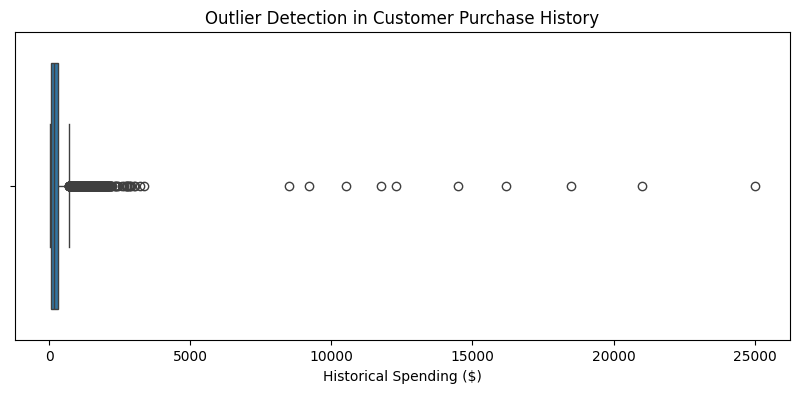

In [ ]:
#mona asghar albloushi

plt.figure(figsize=(10, 4))

sns.boxplot(x=valid_history)

plt.title("Outlier Detection in Customer Purchase History")
plt.xlabel("Historical Spending ($)")
plt.show()

#highest introduced value is $25,000
#most of the original values may appear compressed toward the left side.

Examine the distribution

In [ ]:
#mona asghar albloushi
print("History Descriptive Statistics:")
display(valid_history.describe())


#This helps us distinguish potentially legitimate
#high-spending customers from unusually extreme values.



History Descriptive Statistics:


,history
count,63973.0
mean,244.376701
std,320.333052
min,29.99
25%,64.69
50%,158.14
75%,325.79
max,25000.0


Duplicate Record Detection

In [ ]:
#mona asghar albloushi
#Count duplicate records

# Detect exact duplicate rows
duplicate_mask = df.duplicated()

# Count duplicates
duplicate_count = duplicate_mask.sum()

# Calculate percentage
duplicate_percentage = (
    duplicate_count / len(df)
) * 100

print("Total Records:", len(df))
print("Duplicate Records:", duplicate_count)
print(
    "Duplicate Percentage:",
    round(duplicate_percentage, 2), "%"
)


#Display duplicate examples
# Display examples of duplicated rows
display(df[df.duplicated(keep=False)].head(10))


Total Records: 64000
Duplicate Records: 6583
Duplicate Percentage: 10.29 %


,recency,history,used_discount,used_bogo,zip_code,is_referral,channel,offer,conversion
16,5.0,29.99,1.0,0.0,Surburban,0.0,Phone,Discount,0
20,9.0,29.99,0.0,1.0,Surburban,1.0,Phone,No Offer,0
23,2.0,29.99,0.0,1.0,Urban,1.0,Phone,No Offer,0
33,9.0,29.99,1.0,0.0,Surburban,1.0,Phone,Discount,0
34,3.0,29.99,1.0,0.0,Rural,0.0,Web,Buy One Get One,0
45,10.0,29.99,1.0,0.0,Surburban,0.0,Phone,No Offer,0
52,7.0,29.99,0.0,1.0,Urban,1.0,Phone,Discount,0
79,2.0,29.99,0.0,1.0,Surburban,0.0,Phone,Discount,0
107,12.0,29.99,0.0,1.0,Urban,1.0,Web,No Offer,0
114,4.0,29.99,0.0,1.0,Urban,1.0,Web,Buy One Get One,0


Display all categorical values

In [ ]:
#mona asghar albloushi

categorical_columns = [
    "zip_code",
    "channel",
    "offer"
]

for col in categorical_columns:
    print(f"\nColumn: {col}")
    print("Unique Values:")
    print(df[col].unique())

    print("\nValue Counts:")
    print(df[col].value_counts(dropna=False))

#We need to check for
#spelling errors, inconsistent labels, unexpected categories, and missing values.


Column: zip_code
Unique Values:
['Surburban' 'Rural' 'Urban' nan]

Value Counts:
zip_code
Surburban    28767
Urban        25652
Rural         9563
NaN             18
Name: count, dtype: int64

Column: channel
Unique Values:
['Phone' 'Web' 'Multichannel' nan 'Satellite']

Value Counts:
channel
Web             28209
Phone           28009
Multichannel     7761
NaN                18
Satellite           3
Name: count, dtype: int64

Column: offer
Unique Values:
['Buy One Get One' 'No Offer' 'Discount']

Value Counts:
offer
Buy One Get One    21387
Discount           21307
No Offer           21306
Name: count, dtype: int64


Validate categorical values

In [ ]:
#Mona Asghar Albloushi
# Define expected categories
valid_categories = {
    "zip_code": ["Urban", "Rural", "Suburban"],
    "channel": ["Web", "Phone", "Multichannel"],
    "offer": ["Discount", "Buy One Get One", "No Offer"]
}

# Check unexpected categories
for col, allowed_values in valid_categories.items():

    unexpected = (
        df[col].notna()
        & ~df[col].isin(allowed_values)
    )

    print(f"\nColumn: {col}")
    print("Unexpected Values:", unexpected.sum())

    print("Unexpected Categories:")
    print(df.loc[unexpected, col].value_counts())

#Surburban typo existed in the original dataset
#It is not one of the 15 newly introduced invalid values.
#Surburban instead of Suburban==>zip code
#3 records containing Satellite==>channel
#	No introduced category issues==>offer


Column: zip_code
Unexpected Values: 28767
Unexpected Categories:
zip_code
Surburban    28767
Name: count, dtype: int64

Column: channel
Unexpected Values: 3
Unexpected Categories:
channel
Satellite    3
Name: count, dtype: int64

Column: offer
Unexpected Values: 0
Unexpected Categories:
Series([], Name: count, dtype: int64)


Data Quality Detection

In [ ]:
#Mona Asghar Albloushi

# Final verification of Data Quality Detection
print("Dataset Shape:", df.shape)
print("Missing Values:", df.isna().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("\nChannel Categories:")
print(df["channel"].value_counts(dropna=False))

print("\nZip Code Categories:")
print(df["zip_code"].value_counts(dropna=False))


Dataset Shape: (64000, 9)
Missing Values: 112
Duplicate Rows: 6583

Channel Categories:
channel
Web             28209
Phone           28009
Multichannel     7761
NaN                18
Satellite           3
Name: count, dtype: int64

Zip Code Categories:
zip_code
Surburban    28767
Urban        25652
Rural         9563
NaN             18
Name: count, dtype: int64


Part 2 — Data Cleaning

In [ ]:
#Shaikah Ali Omran
#Part 2 Data Cleaning


# Convert recency to numeric

df["recency"] = pd.to_numeric(
    df["recency"].astype("string")
    .str.replace(r"\s*days\s*$", "", regex=True),
    errors="coerce"
)

# Remove dollar signs from history
df["history"] = df["history"].str.replace(
    "$", "", regex=False
)

# Convert history to numeric
df["history"] = pd.to_numeric(
    df["history"], errors="coerce"
)

# Convert Yes/No into 1/0
df["used_discount"] = df["used_discount"].replace({
    "Yes": 1,
    "No": 0
})

df["used_discount"] = pd.to_numeric(
    df["used_discount"], errors="coerce"
)

# Fix spelling mistake
df["zip_code"] = df["zip_code"].replace(
    "Surburban", "Suburban"
)

print(df.dtypes)

recency          Float64
history          float64
used_discount    float64
used_bogo        float64
zip_code          object
is_referral      float64
channel           object
offer             object
conversion         int64
dtype: object


In [ ]:
#Shaikah Ali Omran

# Fix invalid values
# Explanation: We change invalid values into missing values because we don't know their correct original values. We can then handle them using an appropriate method.

# Invalid recency values
df.loc[~df["recency"].between(1, 12), "recency"] = np.nan

# Negative historical spending
df.loc[df["history"] < 0, "history"] = np.nan

# Invalid binary values
df.loc[~df["used_bogo"].isin([0, 1]), "used_bogo"] = np.nan
df.loc[~df["is_referral"].isin([0, 1]), "is_referral"] = np.nan

# Invalid channel categories
valid_channels = ["Web", "Phone", "Multichannel"]

df.loc[~df["channel"].isin(valid_channels), "channel"] = np.nan

print(df.isnull().sum())


recency          19
history          27
used_discount    12
used_bogo        15
zip_code         18
is_referral      15
channel          21
offer             0
conversion        0
dtype: int64


In [ ]:
#Shaikah Ali Omran

#Handle missing values
#Median: Middle value, useful for numerical data because it is less affected by outliers.
#Mode: Most frequent value, useful for categorical and binary columns.




# Fill numeric columns using the median
df["recency"] = df["recency"].fillna(df["recency"].median())
df["history"] = df["history"].fillna(df["history"].median())

# Fill categorical/binary columns using the mode
columns = [
    "used_discount",
    "used_bogo",
    "is_referral",
    "zip_code",
    "channel"
]

for col in columns:
    df[col] = df[col].fillna(df[col].mode()[0])

# Convert integer columns to integers
for col in ["recency", "used_discount", "used_bogo", "is_referral"]:
    df[col] = df[col].astype(int)

print(df.isnull().sum())


recency          0
history          0
used_discount    0
used_bogo        0
zip_code         0
is_referral      0
channel          0
offer            0
conversion       0
dtype: int64


In [ ]:
#Shaikah Ali Omran

#Handle duplicate rows
##Explanation: Your dataset has no unique customer ID.
#Two customers could have exactly the same recorded values, so we cannot confidently identify duplicates as errors.


# Check duplicates after cleaning
duplicates = df.duplicated().sum()

print("Duplicate rows:", duplicates)
print("Total rows:", len(df))


Duplicate rows: 6598
Total rows: 64000


In [ ]:
#Shaikah Ali Omran
# Count duplicate rows
print("Number of duplicates:", df.duplicated().sum())

# Display duplicate rows
display(df[df.duplicated()].head(10))

#keeping the duplicates since they could be different customers with the same inforamtion


Number of duplicates: 6598


,recency,history,used_discount,used_bogo,zip_code,is_referral,channel,offer,conversion
149,2,29.99,0,1,Suburban,0,Phone,Discount,0
167,7,29.99,1,0,Suburban,1,Web,Buy One Get One,0
526,10,29.99,1,0,Urban,0,Web,Buy One Get One,0
654,10,29.99,1,0,Urban,0,Web,Buy One Get One,0
792,9,29.99,0,1,Suburban,0,Phone,No Offer,0
807,9,29.99,0,1,Suburban,1,Phone,No Offer,0
883,9,29.99,0,1,Suburban,0,Phone,Buy One Get One,0
924,10,29.99,1,0,Urban,0,Web,Buy One Get One,0
937,6,29.99,0,1,Urban,1,Web,Discount,0
949,9,29.99,0,1,Suburban,0,Phone,Buy One Get One,0


In [ ]:
#Shaikah Ali Omran
#Handle outliers

# Count extreme values
print("Extreme values:", (df["history"] > 3345.93).sum())

# Cap extreme spending at the original dataset maximum
df["history"] = df["history"].clip(upper=3345.93)

print("Maximum spending:", df["history"].max())


Extreme values: 10
Maximum spending: 3345.93


In [ ]:
#Shaikah Ali Omran
#after data cleaning

# Check the cleaned dataset
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nRecency range:")
print(df["recency"].min(), df["recency"].max())

print("\nHistory range:")
print(df["history"].min(), df["history"].max())


Dataset shape: (64000, 9)
Missing values: 0
Duplicate rows: 6598

Data types:
recency            int64
history          float64
used_discount      int64
used_bogo          int64
zip_code          object
is_referral        int64
channel           object
offer             object
conversion         int64
dtype: object

Recency range:
1 12

History range:
29.99 3345.93


Upload Cleaned data

In [ ]:
#Shaikah Ali Omran
#Conversion rate by offer

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the modified dataset
df = pd.read_csv("Orignal-data.csv")

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Display first five rows
display(df.head())

# Check column names and data types
df.info()




Dataset Shape: (64000, 9)


,recency,history,used_discount,used_bogo,zip_code,is_referral,channel,offer,conversion
0,10,142.44,1,0,Surburban,0,Phone,Buy One Get One,0
1,6,329.08,1,1,Rural,1,Web,No Offer,0
2,7,180.65,0,1,Surburban,1,Web,Buy One Get One,0
3,9,675.83,1,0,Rural,1,Web,Discount,0
4,2,45.34,1,0,Urban,0,Web,Buy One Get One,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   recency        64000 non-null  int64  
 1   history        64000 non-null  float64
 2   used_discount  64000 non-null  int64  
 3   used_bogo      64000 non-null  int64  
 4   zip_code       64000 non-null  object 
 5   is_referral    64000 non-null  int64  
 6   channel        64000 non-null  object 
 7   offer          64000 non-null  object 
 8   conversion     64000 non-null  int64  
dtypes: float64(1), int64(5), object(3)
memory usage: 4.4+ MB



Part 3 Exploratory Data Analysis (EDA)



A- Dataset and Campaign Overview

In [ ]:
#Shaikah Ali Omran
#Descriptive Statistics
# Generate descriptive statistics for numerical variables
print("Numerical Descriptive Statistics:")
display(df.describe().round(2))

# Generate descriptive statistics for categorical variables
print("\nCategorical Descriptive Statistics:")
display(df.describe(include=["object"]))


Numerical Descriptive Statistics:


,recency,history,used_discount,used_bogo,is_referral,conversion
count,64000.00,64000.00,64000.00,64000.00,64000.0,64000.00
mean,5.76,242.09,0.55,0.55,0.5,0.15
std,3.51,256.16,0.50,0.50,0.5,0.35
min,1.00,29.99,0.00,0.00,0.0,0.00
25%,2.00,64.66,0.00,0.00,0.0,0.00
50%,6.00,158.11,1.00,1.00,1.0,0.00
75%,9.00,325.66,1.00,1.00,1.0,0.00
max,12.00,3345.93,1.00,1.00,1.0,1.00



Categorical Descriptive Statistics:


,zip_code,channel,offer
count,64000,64000,64000
unique,3,3,3
top,Surburban,Web,Buy One Get One
freq,28776,28217,21387


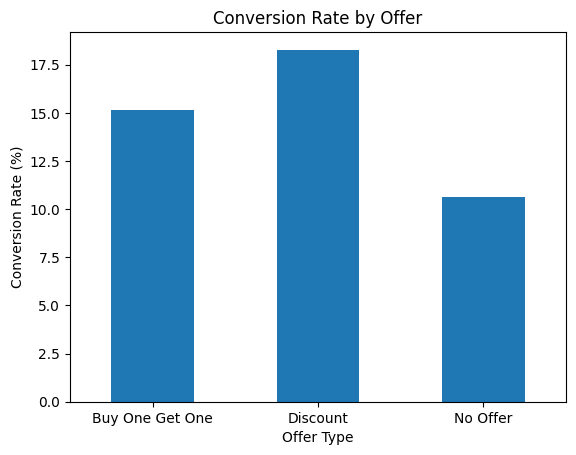

In [ ]:
#Shaikah Ali Omran

# Calculate conversion percentage
conversion_rate = df.groupby("offer")["conversion"].mean() * 100

# Plot
conversion_rate.plot(kind="bar")

plt.title("Conversion Rate by Offer")
plt.xlabel("Offer Type")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.show()

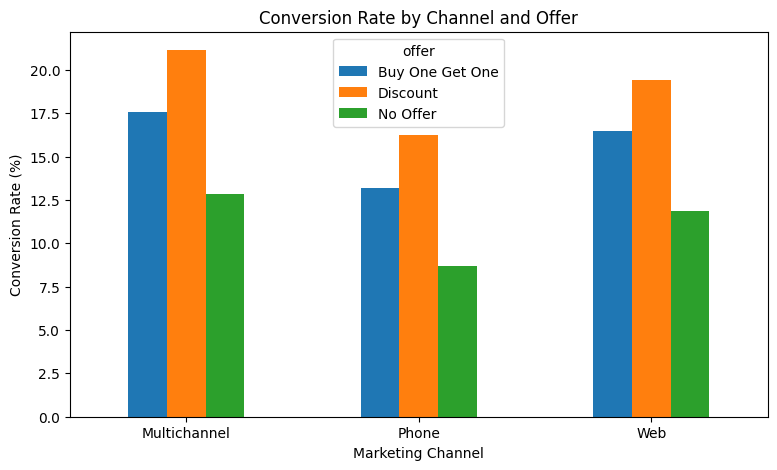

In [ ]:
#Shaikah Ali Omran
#Conversion rate by channel and offer

# Compare conversion rates
channel_rate = df.groupby(
    ["channel", "offer"]
)["conversion"].mean().unstack() * 100

channel_rate.plot(kind="bar", figsize=(9, 5))

plt.title("Conversion Rate by Channel and Offer")
plt.xlabel("Marketing Channel")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.show()



B — Customer Behavior Analysis

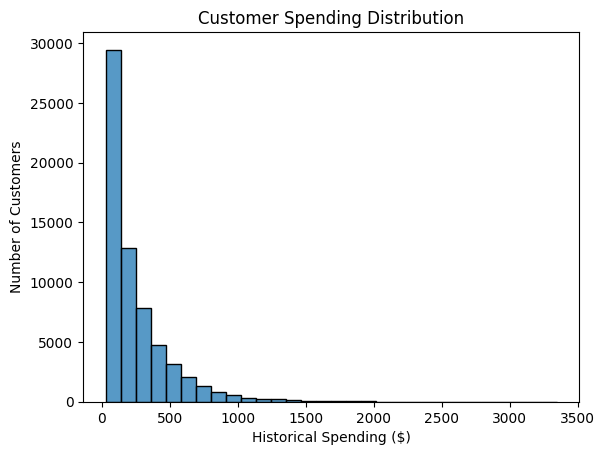

In [ ]:
#Historical spending distribution

# Display spending distribution
sns.histplot(df["history"], bins=30)

plt.title("Customer Spending Distribution")
plt.xlabel("Historical Spending ($)")
plt.ylabel("Number of Customers")
plt.show()


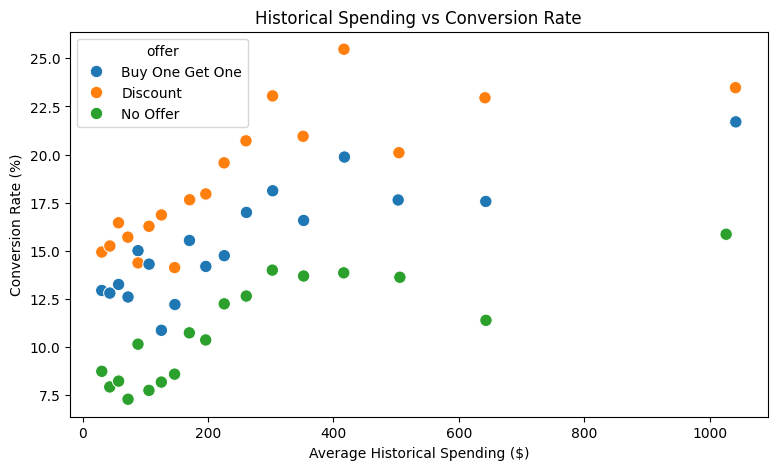

In [ ]:
#Shaikah Ali Omran

#Historical Spending vs. Conversion Rate clustering
# Divide customers into 20 spending groups
spending_groups = pd.qcut(df["history"], 20, duplicates="drop")

# Calculate average spending and conversion rate
plot_data = df.groupby(
    [spending_groups, "offer"], observed=True
).agg(
    avg_spending=("history", "mean"),
    conversion_rate=("conversion", "mean")
).reset_index()

# Convert conversion rate to percentage
plot_data["conversion_rate"] *= 100

# Create scatter plot
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=plot_data,
    x="avg_spending",
    y="conversion_rate",
    hue="offer",
    s=80
)

plt.title("Historical Spending vs Conversion Rate")
plt.xlabel("Average Historical Spending ($)")
plt.ylabel("Conversion Rate (%)")
plt.show()


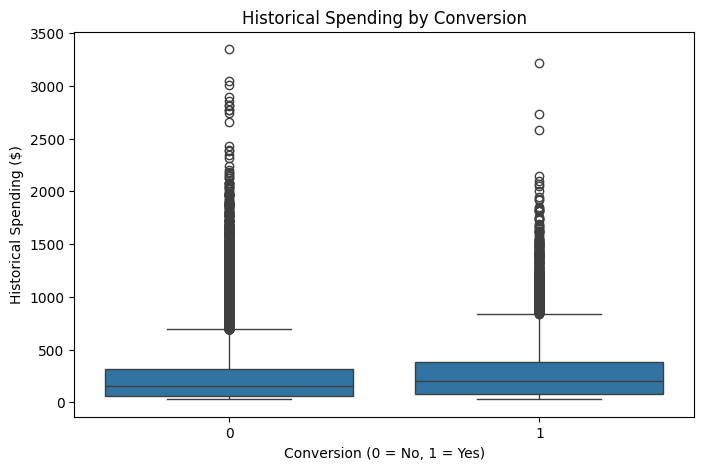

In [ ]:
#Shaikah Ali Omran

# Boxplot: Historical Spending by Conversion
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="conversion", y="history")

plt.title("Historical Spending by Conversion")
plt.xlabel("Conversion (0 = No, 1 = Yes)")
plt.ylabel("Historical Spending ($)")
plt.show()


Part 4 feature engineering

In [ ]:
#Shaikah Ali Omran

#create new features

# Identify customers who purchased recently
df["recent_customer"] = (df["recency"] <= 3).astype(int)

# Identify customers who previously used any promotion
df["used_any_promo"] = (
    (df["used_discount"] == 1) |
    (df["used_bogo"] == 1)
).astype(int)

# Reduce spending skewness
df["history_log"] = np.log1p(df["history"])

# Display the new features
df[["recent_customer", "used_any_promo", "history_log"]].head()


,recent_customer,used_any_promo,history_log
0,0,1,4.965917
1,0,1,5.799335
2,0,1,5.202082
3,0,1,6.517420
4,1,1,3.836006


In [ ]:
#save dataset
#
# Save the prepared dataset
#df.to_csv("brightmart_prepared.csv", index=False)

#print("Dataset saved successfully!")
#print("Final shape:", df.shape)
